# Agency Revenue Intelligence — Exploratory Data Analysis

## Project Objective

Analyze monthly agency revenue, client growth, and revenue composition to understand historical business performance and prepare for time-series forecasting.



## 1. Business Problem

An agency generates revenue through two primary streams:

- Retainer Revenue: Recurring revenue from ongoing client contracts.
- Project Fee Revenue: Revenue generated from individual client projects.

The objective of this analysis is to understand historical revenue performance, identify growth patterns, investigate revenue composition, and prepare the dataset for monthly revenue forecasting.

### Key Business Questions

1. How has recognized agency revenue evolved over time?
2. What proportion of revenue comes from retainers versus project fees?
3. Is revenue growth driven by an increase in active clients?
4. Are there unusual revenue fluctuations or outliers?
5. What historical patterns should inform forecasting models?

### Forecasting Objective

Predict monthly recognized agency revenue using historical business performance and compare statistical and machine learning forecasting approaches.


In [2]:
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:

# ============================================================
# 2. LIBRARY IMPORTS AND CONFIGURATION
# ============================================================

# Data manipulation

import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Date and file handling
from pathlib import Path

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Visualization configuration
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

# Project paths
PROJECT_DIR = Path.cwd()

DATA_DIR = (
    PROJECT_DIR.parent / "data" / "processed_candidate"
)

print("Libraries imported successfully.")
print("Current working directory:", PROJECT_DIR)
print("Data directory:", DATA_DIR)
print("Data directory exists:", DATA_DIR.exists())


Libraries imported successfully.
Current working directory: /Users/nithiii/Downloads/data-science-ai-portfolio/02-deep-learning/agency-revenue-intelligence/notebooks
Data directory: /Users/nithiii/Downloads/data-science-ai-portfolio/02-deep-learning/agency-revenue-intelligence/data/processed_candidate
Data directory exists: True


In [4]:
# ============================================================
# 3. LOAD AND INSPECT AGENCY MONTHLY DATA
# ============================================================

agency_df = pd.read_parquet(
    DATA_DIR / "agency_monthly.parquet"
)

# Convert month column to datetime
agency_df["month"] = pd.to_datetime(agency_df["month"])

# Sort chronologically
agency_df = (
    agency_df
    .sort_values("month")
    .reset_index(drop=True)
)

# Display first five records
display(agency_df.head())

# Dataset dimensions
print("Dataset shape:", agency_df.shape)

# Column information
print("\nDataset information:")
agency_df.info()

# Check missing values
print("\nMissing values:")
display(agency_df.isnull().sum())

,month,recognized_agency_revenue,retainer_revenue_inr,project_fee_revenue_inr,active_clients,new_clients,synthetic_data
0,2023-11-30,0.00,0.00,0.00,0,0,True
1,2023-12-31,"255,422.30","255,422.30",0.00,2,2,True
2,2024-01-31,"415,750.47","323,900.97","91,849.50",3,1,True
3,2024-02-29,"725,575.53","610,881.74","114,693.79",6,3,True
4,2024-03-31,"822,962.38","711,691.26","111,271.12",7,1,True


Dataset shape: (36, 7)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 36 entries, 0 to 35
Data columns (total 7 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   month                      36 non-null     datetime64[ns]
 1   recognized_agency_revenue  36 non-null     float64       
 2   retainer_revenue_inr       36 non-null     float64       
 3   project_fee_revenue_inr    36 non-null     float64       
 4   active_clients             36 non-null     int64         
 5   new_clients                36 non-null     int64         
 6   synthetic_data             36 non-null     bool          
dtypes: bool(1), datetime64[ns](1), float64(3), int64(2)
memory usage: 1.8 KB

Missing values:


month                        0
recognized_agency_revenue    0
retainer_revenue_inr         0
project_fee_revenue_inr      0
active_clients               0
new_clients                  0
synthetic_data               0
dtype: int64

In [5]:
# ============================================================
# 4. DESCRIPTIVE STATISTICS AND BUSINESS-RULE CHECKS
# ============================================================

# 1. Summary statistics
print("REVENUE AND CLIENT METRICS — SUMMARY")
display(
    agency_df[
        [
            "recognized_agency_revenue",
            "retainer_revenue_inr",
            "project_fee_revenue_inr",
            "active_clients",
            "new_clients",
        ]
    ].describe().round(2)
)

# 2. Verify revenue reconciliation
agency_df["revenue_difference"] = (
    agency_df["recognized_agency_revenue"]
    - agency_df["retainer_revenue_inr"]
    - agency_df["project_fee_revenue_inr"]
)

print("\nREVENUE RECONCILIATION")
print(
    "Maximum absolute difference:",
    agency_df["revenue_difference"].abs().max()
)

print(
    "All revenue components reconcile:",
    np.allclose(
        agency_df["recognized_agency_revenue"],
        agency_df["retainer_revenue_inr"]
        + agency_df["project_fee_revenue_inr"],
        atol=0.01,
    )
)

# 3. Verify monthly continuity
expected_months = pd.date_range(
    start=agency_df["month"].min(),
    end=agency_df["month"].max(),
    freq="ME",
)

print("\nDATE CONTINUITY")
print("Expected months:", len(expected_months))
print("Actual months:", agency_df["month"].nunique())
print(
    "All months present:",
    agency_df["month"].reset_index(drop=True).equals(
        pd.Series(expected_months, name="month")
    )
)

# 4. Business activity overview
print("\nBUSINESS ACTIVITY")
print("Total new clients:", agency_df["new_clients"].sum())
print("Latest active clients:", agency_df["active_clients"].iloc[-1])
print(
    "Months with zero revenue:",
    (agency_df["recognized_agency_revenue"] == 0).sum()
)

REVENUE AND CLIENT METRICS — SUMMARY


,recognized_agency_revenue,retainer_revenue_inr,project_fee_revenue_inr,active_clients,new_clients
count,36.00,36.00,36.00,36.00,36.00
mean,"4,234,157.42","3,826,326.14","407,831.28",26.25,1.39
std,"2,450,301.50","2,224,534.86","246,607.34",14.08,1.29
min,0.00,0.00,0.00,0.00,0.00
25%,"2,051,750.11","1,782,675.21","213,991.60",14.50,0.00
50%,"4,318,964.82","3,798,186.56","407,057.70",26.00,1.00
75%,"6,482,415.63","6,018,587.32","579,728.64",39.50,2.00
max,"7,665,218.67","6,987,424.04","885,553.10",46.00,4.00



REVENUE RECONCILIATION
Maximum absolute difference: 8.149072527885437e-10
All revenue components reconcile: True

DATE CONTINUITY
Expected months: 36
Actual months: 36
All months present: True

BUSINESS ACTIVITY
Total new clients: 50
Latest active clients: 45
Months with zero revenue: 1


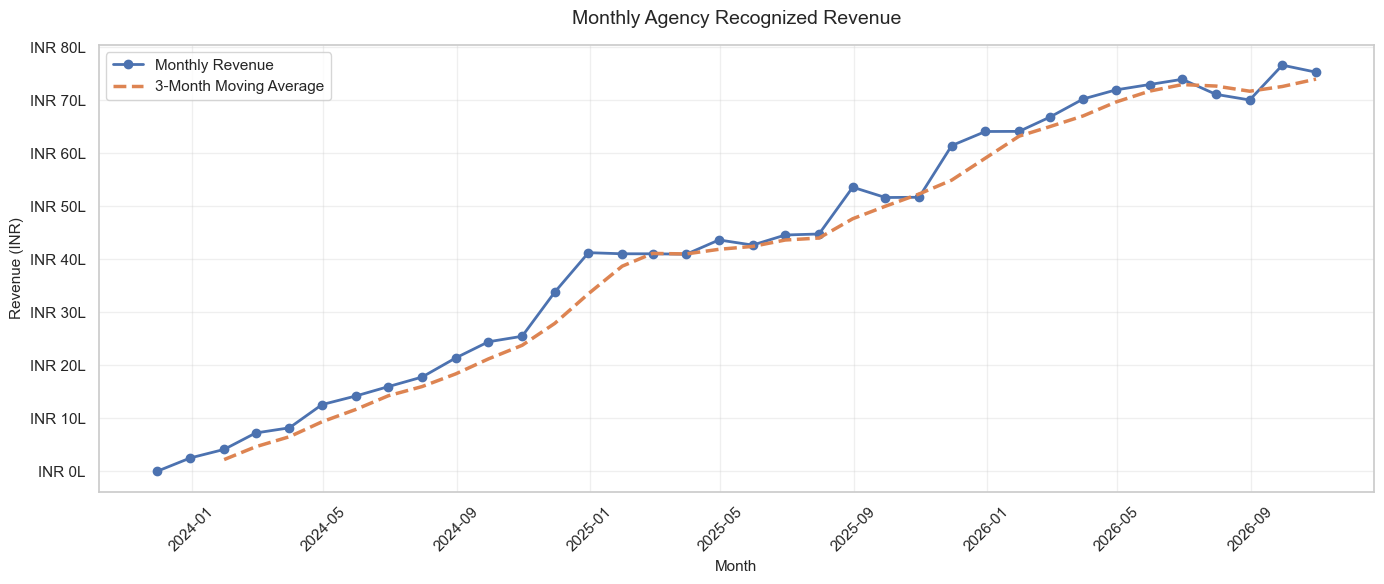

In [6]:
# ============================================================
# 5. MONTHLY AGENCY REVENUE TREND
# ============================================================

fig, ax = plt.subplots(figsize=(14, 6))

# Monthly revenue
ax.plot(
    agency_df["month"],
    agency_df["recognized_agency_revenue"],
    marker="o",
    linewidth=2,
    label="Monthly Revenue",
)

# Three-month moving average
agency_df["revenue_3m_avg"] = (
    agency_df["recognized_agency_revenue"]
    .rolling(window=3)
    .mean()
)

ax.plot(
    agency_df["month"],
    agency_df["revenue_3m_avg"],
    linestyle="--",
    linewidth=2.5,
    label="3-Month Moving Average",
)

# Formatting
ax.set_title("Monthly Agency Recognized Revenue", pad=15)
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (INR)")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"INR {x / 100000:.0f}L")
)

ax.legend()
ax.grid(alpha=0.3)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [7]:
print("Total observations:", len(agency_df))

display(
    agency_df[
        ["month", "recognized_agency_revenue"]
    ].tail(12)
)

Total observations: 36


,month,recognized_agency_revenue
24,2025-11-30,"6,147,724.89"
25,2025-12-31,"6,413,412.79"
26,2026-01-31,"6,415,836.49"
27,2026-02-28,"6,682,153.04"
28,2026-03-31,"7,027,875.41"
29,2026-04-30,"7,198,334.48"
30,2026-05-31,"7,299,708.99"
31,2026-06-30,"7,398,294.02"
32,2026-07-31,"7,114,002.98"
33,2026-08-31,"7,008,055.60"


### Key Observations

- Agency revenue demonstrates an overall upward trend.
- Revenue growth accelerates during late 2024 and early 2025.
- A temporary period of revenue stabilization is visible around INR 40–44 lakh.
- The 3-month moving average smooths short-term fluctuations and highlights the underlying trend.
- The observed growth suggests that client acquisition and recurring retainer revenue may be important forecasting drivers.

**Forecasting implication:** The revenue series exhibits a strong trend. Forecasting models should account for this trend rather than relying only on historical averages.

Start date: 2023-11-30 00:00:00
End date: 2026-10-31 00:00:00
Total months: 36


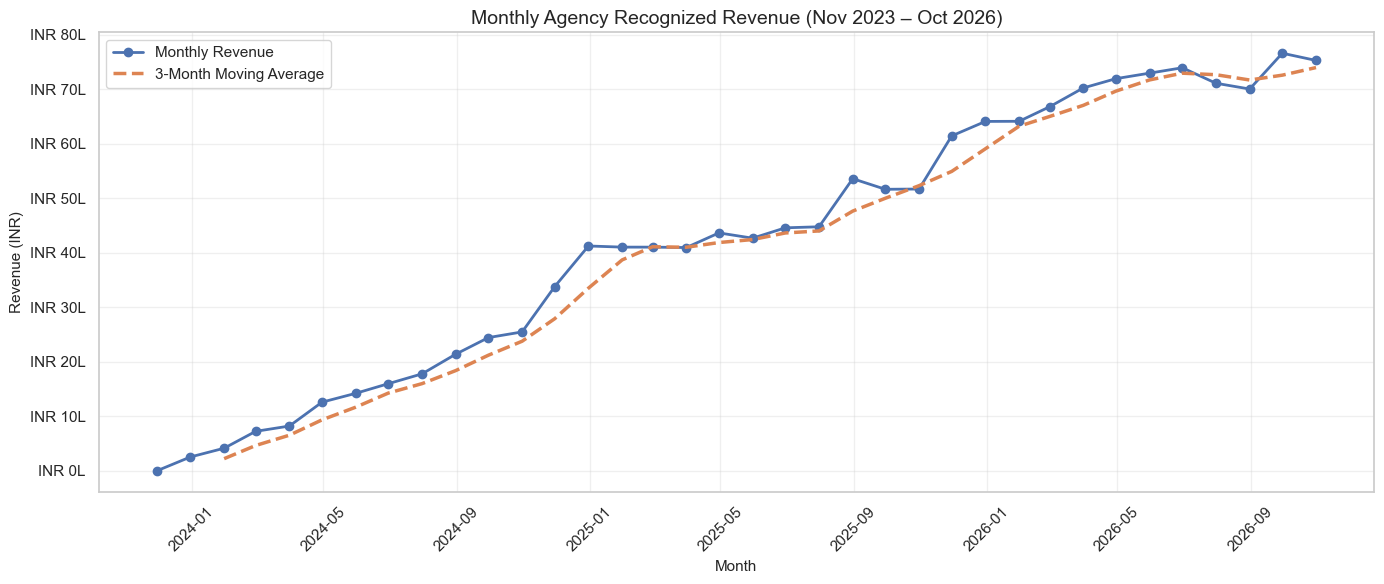

In [8]:
# Verify the complete date range
print("Start date:", agency_df["month"].min())
print("End date:", agency_df["month"].max())
print("Total months:", len(agency_df))

# Recreate the chart using all observations
fig, ax = plt.subplots(figsize=(14, 6))

ax.plot(
    agency_df["month"],
    agency_df["recognized_agency_revenue"],
    marker="o",
    linewidth=2,
    label="Monthly Revenue",
)

revenue_3m_avg = (
    agency_df["recognized_agency_revenue"]
    .rolling(window=3)
    .mean()
)

ax.plot(
    agency_df["month"],
    revenue_3m_avg,
    linestyle="--",
    linewidth=2.5,
    label="3-Month Moving Average",
)

ax.set_title("Monthly Agency Recognized Revenue (Nov 2023 – Oct 2026)")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (INR)")

ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"INR {x / 100000:.0f}L")
)

ax.legend()
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### Key Observations — Monthly Agency Revenue

1. **Overall growth:** Agency revenue demonstrates a strong upward trend over the 36-month observation period.
2. **Initial growth phase:** Revenue increased steadily from November 2023 through December 2024.
3. **Temporary plateau:** Revenue remained relatively stable around ₹41–45 lakh during early to mid-2025.
4. **Renewed growth:** Revenue accelerated from September 2025 and crossed ₹70 lakh by April 2026.
5. **Recent stabilization:** Revenue fluctuated around ₹70–77 lakh during the final six months, reaching approximately ₹75.32 lakh in October 2026.
6. **Moving average:** The 3-month moving average smooths short-term fluctuations and highlights the underlying upward trend.

**Forecasting implications:**

- The revenue series exhibits a strong upward trend.
- Forecasting models should account for trend and potential changes in growth rate.
- Client acquisition, active client count, and revenue composition should be investigated as potential explanatory factors.
- Annual seasonality should be tested rather than assumed, given the limited 36-month history.

Revenue reconciliation check:
All months reconcile: True

Revenue composition across the full period:
Total recognized revenue: ₹152,429,667.17
Total retainer revenue: ₹137,747,741.11
Total project-fee revenue: ₹14,681,926.06
Retainer contribution: 90.37%
Project-fee contribution: 9.63%


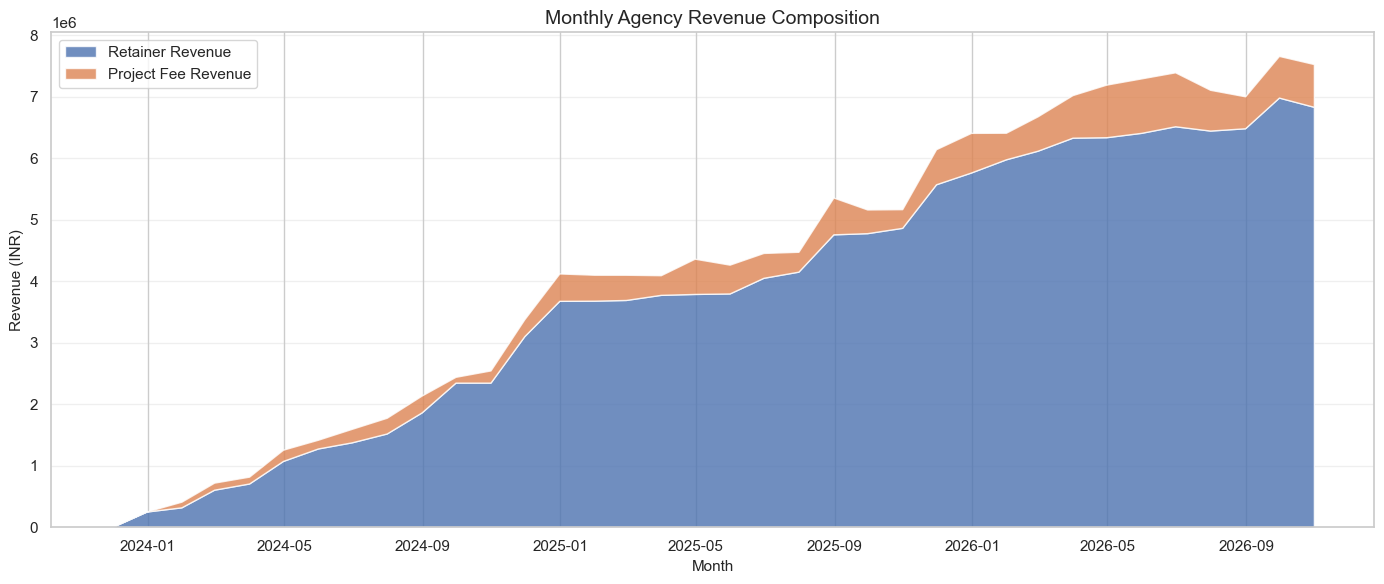

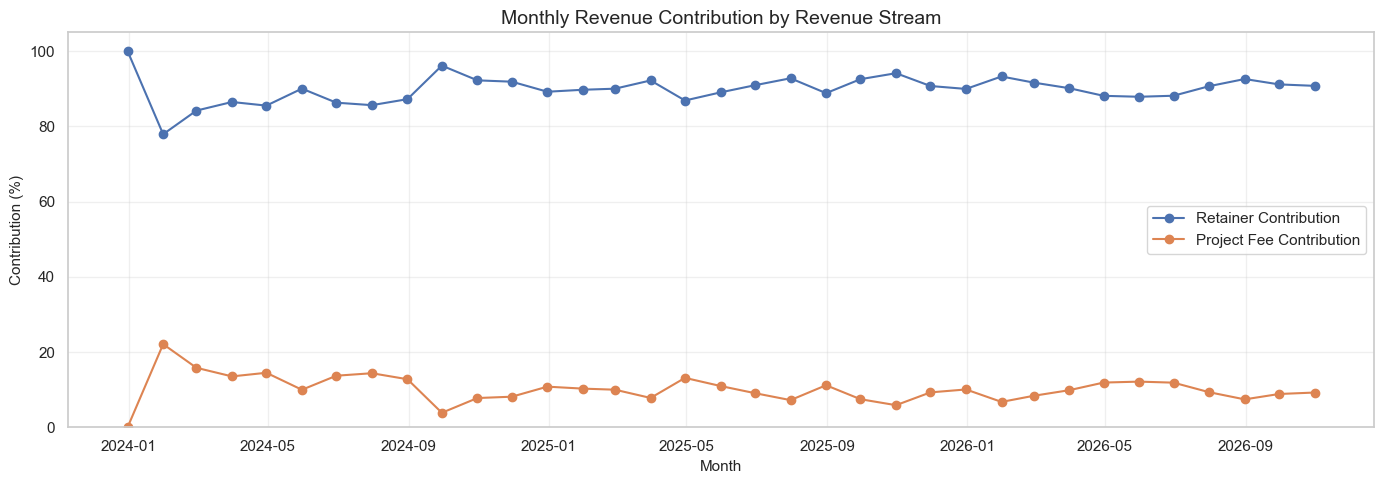

In [9]:

# ============================================================
# 6. REVENUE COMPOSITION ANALYSIS
# ============================================================

# Sort data chronologically
agency_df = agency_df.sort_values("month").copy()

# Verify that revenue components reconcile with total revenue
agency_df["revenue_difference"] = (
    agency_df["recognized_agency_revenue"]
    - agency_df["retainer_revenue_inr"]
    - agency_df["project_fee_revenue_inr"]
)

print("Revenue reconciliation check:")
print(
    "All months reconcile:",
    np.allclose(agency_df["revenue_difference"], 0, atol=0.01)
)

# Calculate aggregate revenue contribution
total_revenue = agency_df["recognized_agency_revenue"].sum()
total_retainer = agency_df["retainer_revenue_inr"].sum()
total_project = agency_df["project_fee_revenue_inr"].sum()

retainer_share = (
    total_retainer / total_revenue * 100
    if total_revenue > 0 else 0
)

project_share = (
    total_project / total_revenue * 100
    if total_revenue > 0 else 0
)

print("\nRevenue composition across the full period:")
print(f"Total recognized revenue: ₹{total_revenue:,.2f}")
print(f"Total retainer revenue: ₹{total_retainer:,.2f}")
print(f"Total project-fee revenue: ₹{total_project:,.2f}")
print(f"Retainer contribution: {retainer_share:.2f}%")
print(f"Project-fee contribution: {project_share:.2f}%")

# Calculate monthly revenue contribution percentages
agency_df["retainer_share_pct"] = np.where(
    agency_df["recognized_agency_revenue"] > 0,
    agency_df["retainer_revenue_inr"]
    / agency_df["recognized_agency_revenue"] * 100,
    np.nan
)

agency_df["project_share_pct"] = np.where(
    agency_df["recognized_agency_revenue"] > 0,
    agency_df["project_fee_revenue_inr"]
    / agency_df["recognized_agency_revenue"] * 100,
    np.nan
)

# Plot monthly revenue composition
plt.figure(figsize=(14, 6))

plt.stackplot(
    agency_df["month"],
    agency_df["retainer_revenue_inr"],
    agency_df["project_fee_revenue_inr"],
    labels=["Retainer Revenue", "Project Fee Revenue"],
    alpha=0.8
)

plt.title("Monthly Agency Revenue Composition")
plt.xlabel("Month")
plt.ylabel("Revenue (INR)")
plt.legend(loc="upper left")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

# Plot monthly revenue contribution percentages
plt.figure(figsize=(14, 5))

plt.plot(
    agency_df["month"],
    agency_df["retainer_share_pct"],
    label="Retainer Contribution",
    marker="o"
)

plt.plot(
    agency_df["month"],
    agency_df["project_share_pct"],
    label="Project Fee Contribution",
    marker="o"
)

plt.title("Monthly Revenue Contribution by Revenue Stream")
plt.xlabel("Month")
plt.ylabel("Contribution (%)")
plt.ylim(0, 105)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Revenue Composition — Key Observations

- Retainer revenue is the primary contributor to total agency revenue.
- Project-fee revenue provides an additional but smaller revenue stream.
- The monthly contribution of each revenue stream varies over time.
- Revenue reconciliation confirms that retainer and project-fee revenue components sum to recognized agency revenue.
- The agency's revenue model is predominantly retainer-driven, highlighting the importance of client retention and recurring contracts.

In [10]:
print("REVENUE COMPOSITION SUMMARY")
print("-" * 40)

print(f"Total revenue: ₹{total_revenue:,.2f}")
print(f"Retainer revenue: ₹{total_retainer:,.2f}")
print(f"Project-fee revenue: ₹{total_project:,.2f}")

print(f"\nRetainer share: {retainer_share:.2f}%")
print(f"Project-fee share: {project_share:.2f}%")

print("\nMonthly contribution summary:")
print(
    agency_df[["retainer_share_pct", "project_share_pct"]]
    .describe()
    .round(2)
)

print("\nLatest 6 months:")
print(
    agency_df[
        ["month", "recognized_agency_revenue",
         "retainer_revenue_inr", "project_fee_revenue_inr",
         "retainer_share_pct", "project_share_pct"]
    ].tail(6).to_string(index=False)
)

REVENUE COMPOSITION SUMMARY
----------------------------------------
Total revenue: ₹152,429,667.17
Retainer revenue: ₹137,747,741.11
Project-fee revenue: ₹14,681,926.06

Retainer share: 90.37%
Project-fee share: 9.63%

Monthly contribution summary:
       retainer_share_pct  project_share_pct
count               35.00              35.00
mean                89.85              10.15
std                  3.77               3.77
min                 77.91               0.00
25%                 87.99               7.96
50%                 90.03               9.97
75%                 92.04              12.01
max                100.00              22.09

Latest 6 months:
     month  recognized_agency_revenue  retainer_revenue_inr  project_fee_revenue_inr  retainer_share_pct  project_share_pct
2026-05-31               7,299,708.99          6,414,155.89               885,553.10               87.87              12.13
2026-06-30               7,398,294.02          6,521,118.60               877,1

### Revenue Composition — Key Observations

1. Total recognized agency revenue across the 36-month period is ₹152.43 million.
2. Retainer revenue contributes 90.37% of total revenue, while project-fee revenue contributes 9.63%.
3. Across the 35 months with positive revenue, the average monthly retainer contribution is 89.85%.
4. Monthly retainer contribution ranges from 77.91% to 100%, showing variation in the revenue mix.
5. During the latest six months, retainer contribution remained relatively stable between 87.87% and 92.59%.
6. Revenue reconciliation confirms that retainer and project-fee components sum to recognized agency revenue.

**Business takeaway:** The agency's revenue is predominantly retainer-driven. Client retention, contract renewals, and recurring revenue stability are therefore important business considerations.

In [11]:
# ============================================================
# 7. CLIENT ACTIVITY AND REVENUE RELATIONSHIP
# ============================================================

# Calculate revenue per active client
agency_df["revenue_per_active_client"] = np.where(
    agency_df["active_clients"] > 0,
    agency_df["recognized_agency_revenue"] / agency_df["active_clients"],
    np.nan
)

# Calculate monthly revenue growth
agency_df["revenue_growth_pct"] = (
    agency_df["recognized_agency_revenue"]
    .pct_change() * 100
)

# Summary statistics
print("CLIENT ACTIVITY AND REVENUE SUMMARY")
print("-" * 45)

print(agency_df[
    ["active_clients", "new_clients",
     "recognized_agency_revenue", "revenue_per_active_client"]
].describe().round(2))

# Correlation analysis
correlation = agency_df[
    ["active_clients", "new_clients", "recognized_agency_revenue"]
].corr()

print("\nCorrelation Matrix:")
print(correlation.round(3))

CLIENT ACTIVITY AND REVENUE SUMMARY
---------------------------------------------
       active_clients  new_clients  recognized_agency_revenue  \
count           36.00        36.00                      36.00   
mean            26.25         1.39               4,234,157.42   
std             14.08         1.29               2,450,301.50   
min              0.00         0.00                       0.00   
25%             14.50         0.00               2,051,750.11   
50%             26.00         1.00               4,318,964.82   
75%             39.50         2.00               6,482,415.63   
max             46.00         4.00               7,665,218.67   

       revenue_per_active_client  
count                      35.00  
mean                  154,538.50  
std                    15,769.54  
min                   117,566.05  
25%                   140,891.83  
50%                   162,978.04  
75%                   166,394.96  
max                   171,388.92  

Correlation Matr

In [12]:
print("COMPLETE CORRELATION MATRIX")
print("-" * 40)

corr = agency_df[
    [
        "active_clients",
        "new_clients",
        "recognized_agency_revenue"
    ]
].corr()

for col in corr.columns:
    print(f"\n{col}:")
    for row in corr.index:
        print(f"  {row}: {corr.loc[row, col]:.4f}")

COMPLETE CORRELATION MATRIX
----------------------------------------

active_clients:
  active_clients: 1.0000
  new_clients: -0.0682
  recognized_agency_revenue: 0.9981

new_clients:
  active_clients: -0.0682
  new_clients: 1.0000
  recognized_agency_revenue: -0.0791

recognized_agency_revenue:
  active_clients: 0.9981
  new_clients: -0.0791
  recognized_agency_revenue: 1.0000


/var/folders/00/9ynj9xts727dx08n754vj79h0000gn/T/ipykernel_4842/440160399.py:31: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/nithiii/Downloads/data-science-ai-portfolio/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


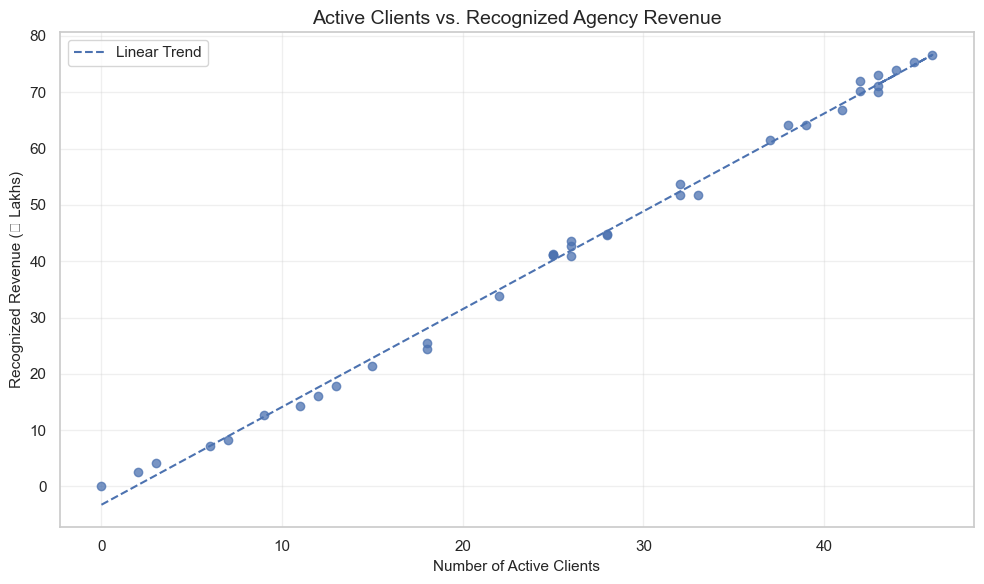

In [13]:
# ============================================================
# 8. ACTIVE CLIENTS VS RECOGNIZED REVENUE
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    agency_df["active_clients"],
    agency_df["recognized_agency_revenue"] / 100000,
    alpha=0.75
)

# Add a linear trend line
x = agency_df["active_clients"]
y = agency_df["recognized_agency_revenue"] / 100000

slope, intercept = np.polyfit(x, y, 1)

plt.plot(
    x,
    slope * x + intercept,
    linestyle="--",
    label="Linear Trend"
)

plt.title("Active Clients vs. Recognized Agency Revenue")
plt.xlabel("Number of Active Clients")
plt.ylabel("Recognized Revenue (₹ Lakhs)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Active Clients vs. Recognized Revenue — Key Observations

1. The scatter plot shows a clear positive linear relationship between active clients and recognized agency revenue.
2. Pearson correlation is 0.9981, indicating an extremely strong positive association.
3. Revenue generally increases as the active client base expands.
4. This pattern is consistent with the agency's retainer-driven business model.
5. The relationship is observational and does not independently establish causation.

**Business takeaway:** Maintaining and expanding the active client base is closely associated with agency revenue growth. Client retention and recurring contract management are important business priorities.


In [14]:
# ============================================================
# 9. NEW CLIENT ACQUISITION VS REVENUE GROWTH
# ============================================================

# Calculate month-over-month revenue growth
agency_df["revenue_growth_pct"] = (
    agency_df["recognized_agency_revenue"]
    .pct_change() * 100
)

# Exclude months where previous month's revenue was zero
growth_df = agency_df[
    agency_df["recognized_agency_revenue"].shift(1) > 0
].copy()

print("NEW CLIENT ACQUISITION VS REVENUE GROWTH")
print("-" * 50)

print(
    growth_df[
        ["month", "new_clients", "revenue_growth_pct"]
    ].describe().round(2)
)

print("\nCorrelation:")
print(
    growth_df[
        ["new_clients", "revenue_growth_pct"]
    ].corr().round(4)
)

NEW CLIENT ACQUISITION VS REVENUE GROWTH
--------------------------------------------------
                               month  new_clients  revenue_growth_pct
count                             34        34.00               34.00
mean   2025-06-15 10:35:17.647058944         1.41               11.72
min              2024-01-31 00:00:00         0.00               -3.84
25%              2024-10-07 18:00:00         0.00                0.05
50%              2025-06-15 00:00:00         1.00                4.39
75%              2026-02-21 00:00:00         2.00               14.00
max              2026-10-31 00:00:00         4.00               74.52
std                              NaN         1.31               18.64

Correlation:
                    new_clients  revenue_growth_pct
new_clients                1.00                0.48
revenue_growth_pct         0.48                1.00


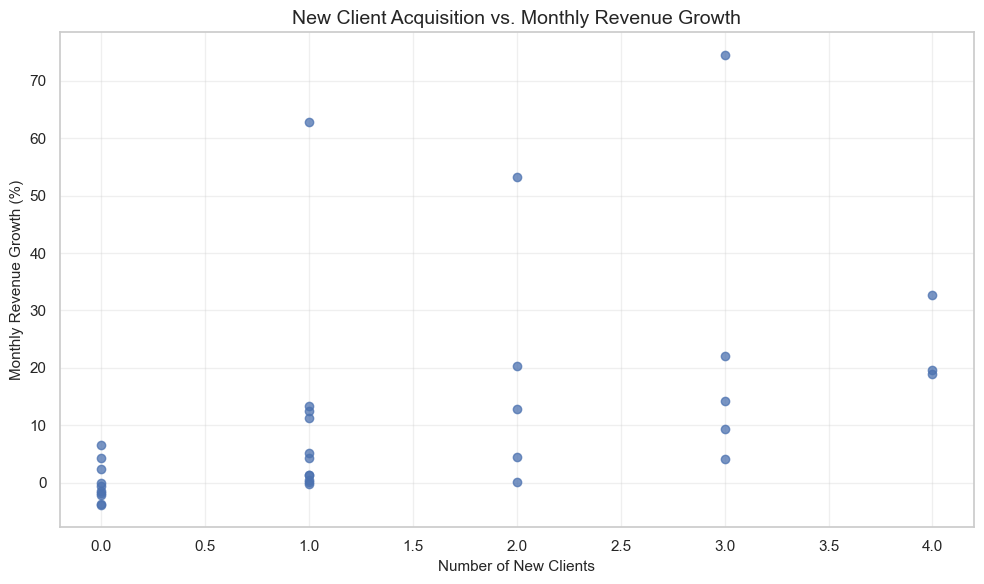

In [15]:
# ============================================================
# 10. NEW CLIENTS VS MONTHLY REVENUE GROWTH
# ============================================================

plt.figure(figsize=(10, 6))

plt.scatter(
    growth_df["new_clients"],
    growth_df["revenue_growth_pct"],
    alpha=0.75
)

plt.title("New Client Acquisition vs. Monthly Revenue Growth")
plt.xlabel("Number of New Clients")
plt.ylabel("Monthly Revenue Growth (%)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### New Client Acquisition vs. Revenue Growth — Key Observations

1. New-client acquisition has a moderate positive correlation (0.48) with monthly revenue growth.
2. Months with zero new clients generally show relatively low or negative revenue growth.
3. Higher client acquisition is often associated with stronger revenue growth, although the relationship is not consistent.
4. Considerable variation exists in revenue growth for the same number of newly acquired clients.
5. An unusually high revenue growth observation of approximately 74.52% requires further investigation.

**Business takeaway:** New-client acquisition contributes to agency growth, but monthly revenue performance may also depend on existing client revenue, contract values, project fees, and revenue recognition timing.

In [16]:
# Identify unusually high revenue growth months

print(
    growth_df[
        growth_df["revenue_growth_pct"] > 30
    ][
        [
            "month",
            "new_clients",
            "recognized_agency_revenue",
            "revenue_growth_pct"
        ]
    ].to_string(index=False)
)

     month  new_clients  recognized_agency_revenue  revenue_growth_pct
2024-01-31            1                 415,750.47               62.77
2024-02-29            3                 725,575.53               74.52
2024-04-30            2               1,260,993.44               53.23
2024-11-30            4               3,382,975.42               32.66


In [17]:
# ============================================================
# 11. REVENUE GROWTH OUTLIER INVESTIGATION
# ============================================================

growth_df["previous_month_revenue"] = (
    growth_df["recognized_agency_revenue"].shift(1)
)

growth_df["absolute_revenue_increase"] = (
    growth_df["recognized_agency_revenue"]
    - growth_df["previous_month_revenue"]
)

high_growth_months = growth_df[
    growth_df["revenue_growth_pct"] > 30
]

print("HIGH REVENUE GROWTH MONTHS")
print("-" * 65)

print(
    high_growth_months[
        [
            "month",
            "new_clients",
            "previous_month_revenue",
            "recognized_agency_revenue",
            "absolute_revenue_increase",
            "revenue_growth_pct"
        ]
    ].to_string(index=False)
)

HIGH REVENUE GROWTH MONTHS
-----------------------------------------------------------------
     month  new_clients  previous_month_revenue  recognized_agency_revenue  absolute_revenue_increase  revenue_growth_pct
2024-01-31            1                     NaN                 415,750.47                        NaN               62.77
2024-02-29            3              415,750.47                 725,575.53                 309,825.06               74.52
2024-04-30            2              822,962.38               1,260,993.44                 438,031.06               53.23
2024-11-30            4            2,550,119.15               3,382,975.42                 832,856.27               32.66


In [18]:
# Calculate previous-month revenue on the complete dataset first
agency_df["previous_month_revenue"] = (
    agency_df["recognized_agency_revenue"].shift(1)
)

agency_df["absolute_revenue_increase"] = (
    agency_df["recognized_agency_revenue"]
    - agency_df["previous_month_revenue"]
)

# Display months with revenue growth above 30%
high_growth_months = agency_df[
    agency_df["revenue_growth_pct"] > 30
]

print("CORRECTED HIGH-GROWTH ANALYSIS")
print("-" * 60)

print(
    high_growth_months[
        [
            "month",
            "new_clients",
            "previous_month_revenue",
            "recognized_agency_revenue",
            "absolute_revenue_increase",
            "revenue_growth_pct"
        ]
    ].to_string(index=False)
)

CORRECTED HIGH-GROWTH ANALYSIS
------------------------------------------------------------
     month  new_clients  previous_month_revenue  recognized_agency_revenue  absolute_revenue_increase  revenue_growth_pct
2023-12-31            2                    0.00                 255,422.30                 255,422.30                 inf
2024-01-31            1              255,422.30                 415,750.47                 160,328.17               62.77
2024-02-29            3              415,750.47                 725,575.53                 309,825.06               74.52
2024-04-30            2              822,962.38               1,260,993.44                 438,031.06               53.23
2024-11-30            4            2,550,119.15               3,382,975.42                 832,856.27               32.66


In [19]:
# Handle zero or missing previous-month revenue

agency_df["revenue_growth_pct"] = np.where(
    agency_df["previous_month_revenue"] > 0,
    (
        (agency_df["recognized_agency_revenue"]
         - agency_df["previous_month_revenue"])
        / agency_df["previous_month_revenue"]
    ) * 100,
    np.nan
)

print("Revenue growth validation:")
print("Infinite values:",
      np.isinf(agency_df["revenue_growth_pct"]).sum())

print("Missing values:",
      agency_df["revenue_growth_pct"].isna().sum())

Revenue growth validation:
Infinite values: 0
Missing values: 2


### Revenue Growth Outlier Investigation — Key Observations

1. February 2024 recorded the highest valid monthly revenue growth at 74.52%.
2. November 2024 recorded the largest absolute revenue increase among the investigated high-growth months, at approximately ₹832,856.
3. Early-stage revenue growth percentages are amplified by the smaller starting revenue base.
4. December 2023 has undefined percentage growth because the previous month's revenue was zero.
5. Zero-baseline and missing-baseline observations must be excluded from percentage growth analysis.

**Business takeaway:** Revenue growth should be evaluated using both percentage growth and absolute revenue increases to avoid misleading conclusions during early business expansion.

In [20]:
# ============================================================
# 12. REVENUE PER ACTIVE CLIENT ANALYSIS
# ============================================================

# Calculate revenue per active client
agency_df["revenue_per_active_client"] = np.where(
    agency_df["active_clients"] > 0,
    agency_df["recognized_agency_revenue"]
    / agency_df["active_clients"],
    np.nan
)

# Summary statistics
print("REVENUE PER ACTIVE CLIENT ANALYSIS")
print("-" * 50)

print(
    agency_df["revenue_per_active_client"]
    .describe()
    .round(2)
)

# First 6 and latest 6 months
print("\nFirst 6 months:")
print(
    agency_df[
        ["month", "active_clients", "revenue_per_active_client"]
    ].head(6).to_string(index=False)
)

print("\nLatest 6 months:")
print(
    agency_df[
        ["month", "active_clients", "revenue_per_active_client"]
    ].tail(6).to_string(index=False)
)

REVENUE PER ACTIVE CLIENT ANALYSIS
--------------------------------------------------
count        35.00
mean    154,538.50
std      15,769.54
min     117,566.05
25%     140,891.83
50%     162,978.04
75%     166,394.96
max     171,388.92
Name: revenue_per_active_client, dtype: float64

First 6 months:
     month  active_clients  revenue_per_active_client
2023-11-30               0                        NaN
2023-12-31               2                 127,711.15
2024-01-31               3                 138,583.49
2024-02-29               6                 120,929.26
2024-03-31               7                 117,566.05
2024-04-30               9                 140,110.38

Latest 6 months:
     month  active_clients  revenue_per_active_client
2026-05-31              43                 169,760.67
2026-06-30              44                 168,143.05
2026-07-31              43                 165,441.93
2026-08-31              43                 162,978.04
2026-09-30              46     

/var/folders/00/9ynj9xts727dx08n754vj79h0000gn/T/ipykernel_4842/3294749261.py:25: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  plt.tight_layout()
/Users/nithiii/Downloads/data-science-ai-portfolio/.venv/lib/python3.9/site-packages/IPython/core/pylabtools.py:152: UserWarning: Glyph 8377 (\N{INDIAN RUPEE SIGN}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


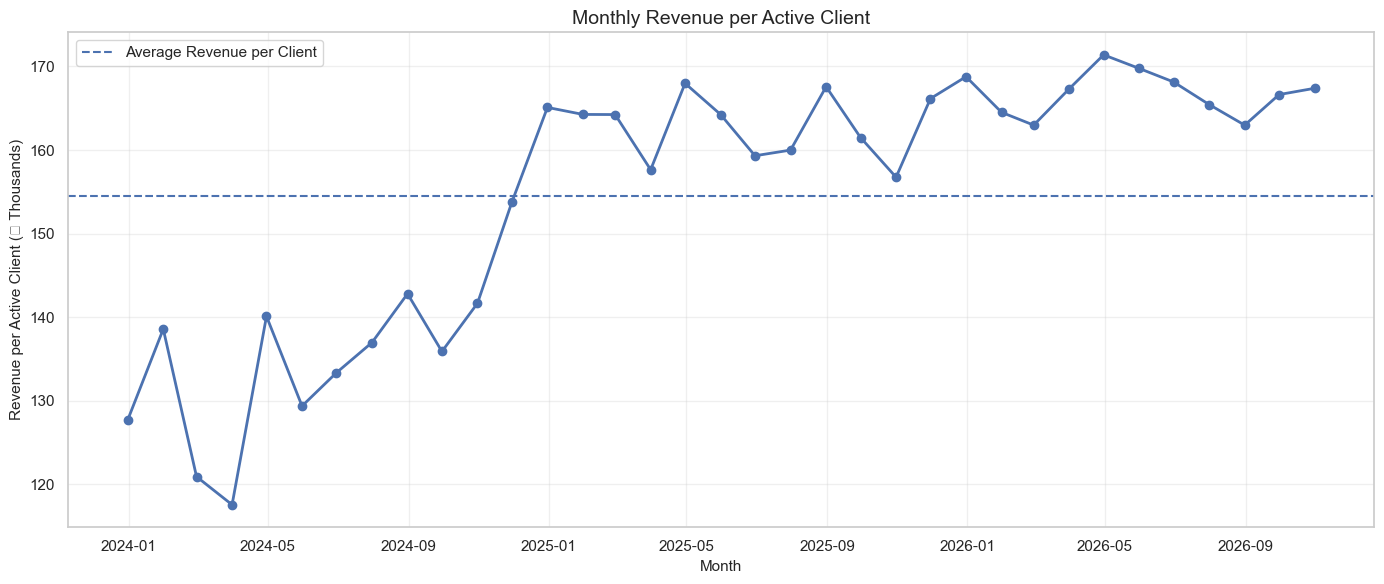

In [21]:
# ============================================================
# 13. REVENUE PER ACTIVE CLIENT TREND
# ============================================================

plt.figure(figsize=(14, 6))

plt.plot(
    agency_df["month"],
    agency_df["revenue_per_active_client"] / 1000,
    marker="o",
    linewidth=2
)

plt.axhline(
    agency_df["revenue_per_active_client"].mean() / 1000,
    linestyle="--",
    label="Average Revenue per Client"
)

plt.title("Monthly Revenue per Active Client")
plt.xlabel("Month")
plt.ylabel("Revenue per Active Client (₹ Thousands)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Revenue per Active Client — Key Observations

1. Average revenue per active client across the observation period is approximately ₹154,539.
2. Revenue per active client increased during the early business-growth period.
3. From 2025 onward, revenue per active client remained relatively stable, generally above ₹157,000.
4. The latest six months show revenue per active client between approximately ₹162,978 and ₹169,761.
5. The agency's revenue growth is associated with both expansion of its active client base and improved revenue per client during its earlier growth period.

**Business takeaway:** The agency has expanded its client base while maintaining relatively stable revenue generation per active client in recent months. This suggests a more established recurring-revenue base.

## Final Exploratory Data Analysis Summary

### 1. Dataset Overview
- 36 months of synthetic agency revenue data, from November 2023 to October 2026.
- Total recognized revenue: ₹152.43 million.
- Average active clients: 26.25.
- Maximum active clients: 46.

### 2. Revenue Trends
- Agency revenue demonstrates substantial growth over the observation period.
- Revenue reaches approximately ₹7.53 million in October 2026.
- Revenue growth becomes relatively stable during the later months.

### 3. Revenue Composition
- Retainer revenue contributes 90.37% of total recognized revenue.
- Project-fee revenue contributes 9.63%.
- The business model is predominantly retainer-driven.

### 4. Client Activity and Revenue
- Active clients have an extremely strong positive correlation with recognized revenue (0.9981).
- New-client acquisition has a moderate positive correlation with monthly revenue growth (0.48).
- New-client acquisition and same-month revenue should not be treated as a causal relationship.

### 5. Revenue per Active Client
- Average revenue per active client: approximately ₹154,539.
- Revenue per active client increased during the early growth period.
- From 2025 onward, revenue per active client remained relatively stable.

### 6. Data Quality and Limitations
- Revenue components reconcile with total recognized agency revenue.
- Percentage growth is undefined when the previous month's revenue is zero.
- The dataset is synthetic; findings demonstrate analytical patterns rather than verified real-world business behaviour.

### 7. Business Conclusions
- Recurring retainer contracts are the primary revenue contributor.
- Active client base expansion is closely associated with revenue growth.
- Revenue per active client has stabilised during the later observation period.
- Client retention, contract renewals, and recurring revenue management are important business considerations.

### 8. Next Steps
- Perform campaign-level revenue EDA.
- Develop and validate forecasting features.
- Evaluate forecasting performance and model explainability.